# Imports

In [1]:
"""Run elasticity on the layered/faulted grid with hole."""
import numpy as np
from pathlib import Path

from create_grid import create_layered_grid_with_hole
from common_functions import solve_and_export
from common_functions import _default_traction
from common_functions import _standard_boundary_masks
from elastic_pb import ElasticProblem
import pygeon as pg



#folder = Path(__file__).parent
folder = Path.cwd()



In [2]:


"""Run the layered-grid-with-hole elasticity workflow.

Parameters
----------
None
    The script uses fixed settings defined inside the function.

Returns
-------
None
    Solution files are written to the results directory.
"""
mesh_size = 0.025

# Step 1: generate layered/faulted grid with hole and layer id.
# Use function defaults for geometry, fault, and hole settings.
sd, cell_layer = create_layered_grid_with_hole(mesh_size=mesh_size, center=(1.5, 0.25))



c:\Users\steto\anaconda3.1\envs\poresct4amm2526\Lib\site-packages\porepy\grids\mdg_generation.py:924: UserWarning: Found 51 fractures outside the domain boundary
  warn(f"Found {num_missing} fractures outside the domain boundary")


In [3]:


# Step 2: solve elasticity and export displacement + layer id.
folder_export = folder / "results"
u = solve_and_export(
    sd,
    folder_export,
    export_name="sol_layered_hole",
    cell_data=[("layer", cell_layer.astype(float))],
)



# measurement

We plot the displacement in the point P(0,1,0). You should write a routine to extract it when the mesh change.

In [4]:
print(u[0][60])
print(u[1][60])



4.635762482906495e-05
-9.931874611270088e-06


# Signature of the function

In [5]:
from scipy.optimize import minimize
import os
import sys
from contextlib import redirect_stdout

In [6]:
%matplotlib inline

In [7]:
def solve_fem_in_memory(sd):
    """
    Risolve il sistema elastico in RAM.
    Nessuna operazione di I/O su disco.
    """
    # Step 1: define material parameters and standard boundary masks.
    lambda_ = 1.0       
    mu = 0.5            
    param = {pg.LAME_LAMBDA: lambda_, pg.LAME_MU: mu}   
    bottom, top = _standard_boundary_masks(sd)          

    # Step 2: assemble and solve the discrete elasticity system.
    elastic_pb = ElasticProblem(sd)                                       
    A, b = elastic_pb.assemble_problem(param, _default_traction, top)   
    u, sigma = elastic_pb.solve_linear_system(A, b, bottom)             

    # Nessun export_solution qui!
    return u

In [8]:
import numpy as np
import matplotlib.tri as mtri

import numpy as np
from scipy.interpolate import griddata

import os
from contextlib import redirect_stdout

def extract_displacement_interpolated(sd, u, target_point=(0.0, 1.0)):
    """
    Interpola lo spostamento al target_point partendo dalla nuvola di nodi.
    Indipendente dalla topologia della mesh (non richiede array di triangoli).
    """
    # 1. Estraiamo le coordinate dei nodi (assumendo sd.nodes sia 2xN)
    x_nodes = sd.nodes[0, :]
    y_nodes = sd.nodes[1, :]
    
    # Creiamo un array Nx2 con le coordinate di tutti i nodi
    points = np.column_stack((x_nodes, y_nodes))
    
    # 2. Interpolazione Lineare (precisa, basata sui nodi circostanti)
    ux_target = griddata(points, u[0, :], target_point, method='linear')
    uy_target = griddata(points, u[1, :], target_point, method='linear')
    
    # 3. Gestione di sicurezza sui bordi
    # Se il target_point è appena fuori dalla mesh (es. deformazione estrema o errore mesher),
    # griddata lineare restituisce NaN. In tal caso facciamo un fallback sul nodo più vicino.
    if np.isnan(ux_target) or np.isnan(uy_target):
        ux_target = griddata(points, u[0, :], target_point, method='nearest')
        uy_target = griddata(points, u[1, :], target_point, method='nearest')
        
    # Restituiamo il vettore come float standard
    return np.array([float(ux_target), float(uy_target)])



def evaluation_cost_function(center, mesh_size, measured_disp, target_point=(0.0, 1.0)):
    cx, cy = center
    
    try:
        # Generazione mesh in memoria
        sd, _ = create_layered_grid_with_hole(mesh_size=mesh_size, center=(cx, cy))
        
        # Soluzione in memoria (senza passare cartelle di export)
        u = solve_fem_in_memory(sd)
        
        # Estrazione (usando la funzione interpolata discussa prima)
        simulated_disp = extract_displacement_interpolated(sd, u, target_point=target_point)
        
        # Errore relativo
        diff = simulated_disp - np.array(measured_disp)
        error = np.linalg.norm(diff) / (np.linalg.norm(measured_disp) + 1e-12)
        return error
        
    except Exception as e:
        
         print(f"⚠️ [DEBUG] Fallimento a ({cx:.2f}, {cy:.2f}) | Tipo: {type(e).__name__} | Dettaglio: {e}")
         return np.inf

In [9]:
import numpy as np
from pathlib import Path
from scipy.optimize import minimize
from concurrent.futures import ProcessPoolExecutor, as_completed
import time

class EarlyStopException(Exception):
    pass

# Funzione di early stop per l'ottimizzazione locale
def make_cost_with_early_stop(mesh_size, measured_disp, tol=1e-3):
    def cost(center):
        err = evaluation_cost_function(center, mesh_size, measured_disp)
        if err < tol:
            raise EarlyStopException(center, err)
        return err
    return cost

def eval_single_point(cx, cy, mesh_size, measured_disp):
    """Wrapper per il multiprocessing, non richiede export_folder"""
    err = evaluation_cost_function((cx, cy), mesh_size, measured_disp)
    return {'center': (cx, cy), 'error': err}

def GroupSolutionCP1(measured_displacement, test_id=1, target_point=(0.0, 1.0)):
    print("\nStarting inverse Multi-Grid with Multi-Start (Memory-Optimized)...")
    export_folder = Path.cwd() / "opt_final_results"
    export_folder.mkdir(exist_ok=True)
    
    # File per il log sequenziale dei risultati intermedi
    log_file_path = export_folder / f"optimization_log_test_{test_id}.txt"
    
    coarse_mesh_size = 0.1 #<-------------------------------------- Da giocare con questo parametro per bilanciare velocità e precisione nella fase 1
    refined_mesh_size = 0.04 #<-------------------------------------- Da giocare con questo parametro per bilanciare velocità e precisione nella fase 2
    
    # =====================================================================
    # PHASE 1: Scansione (In-Memory)
    # =====================================================================
    print("--> PHASE 1: Scanning Coarse Grid (sequential)...")

    t0=time.time()
    x_vals = np.linspace(0.3, 1.7, 6)
    y_vals = np.linspace(0.3, 0.7, 5)
    grid_points = [(cx, cy) for cx in x_vals for cy in y_vals]
    
    coarse_results = []
    
    for i, (cx, cy) in enumerate(grid_points):
        err = evaluation_cost_function((cx, cy), coarse_mesh_size, measured_displacement)
        coarse_results.append({'center': (cx, cy), 'error': err})
        print(f"  [{i+1}/{len(grid_points)}] ({cx:.3f}, {cy:.3f}) -> err={err:.4e}")

    # Ordinamento risultati
    coarse_results.sort(key=lambda x: x['error'])
    
    # SALVATAGGIO SEQUENZIALE DEI LOG INTERMEDI
    with open(log_file_path, "w") as f:
        f.write("--- LOG RISULTATI PHASE 1 (Coarse Grid) ---\n")
        f.write("Center_X, Center_Y, Error\n")
        for res in coarse_results:
            f.write(f"{res['center'][0]:.4f}, {res['center'][1]:.4f}, {res['error']:.6e}\n")
            
    top_candidates = [res['center'] for res in coarse_results[:2]]  # Prendiamo i migliori 2 per la fase 2

    print(f"Fase 1: {time.time()-t0:.1f}s")

    # =====================================================================
    # PHASE 2: Ottimizzazione Locale (Sequenziale In-Memory)
    # =====================================================================
    print("\n--> PHASE 2: Refined Multi-Start Optimization...")
    t1=time.time()
    best_overall_center = None
    best_overall_error = float('inf')
    bounds = [(0.25, 1.75), (0.25, 0.75)]
    
    with open(log_file_path, "a") as f:
        f.write("\n--- LOG RISULTATI PHASE 2 (Nelder-Mead) ---\n")

    GOOD_ENOUGH_ERROR = 5e-3  # soglia accettabilità
    
    for idx, start_center in enumerate(top_candidates):
        try: 
            res = minimize(
            fun=make_cost_with_early_stop(refined_mesh_size, measured_displacement, tol=1e-3),
            x0=start_center,
            #args=(refined_mesh_size, measured_displacement),
            method='Nelder-Mead',
            bounds=bounds,
            options={ 'maxiter': 40}
            )

            #Stopping criteria
            if res.fun < GOOD_ENOUGH_ERROR:
                print(f"✅ Converged early at candidate {idx+1}, skipping remaining.")
                best_overall_center = tuple(res.x)
                best_overall_error = res.fun
                break  # esce dal loop sui candidati

        except EarlyStopException as e:
            best_overall_center = tuple(e.args[0])
            best_overall_error = e.args[1]
            continue  # salta gli altri candidati
        
        # Log del risultato dell'ottimizzazione locale
        with open(log_file_path, "a") as f:
            f.write(f"Start: {start_center} -> End: {tuple(res.x)} | Error: {res.fun:.6e}\n")
            
        if res.fun < best_overall_error:
            best_overall_error = res.fun
            best_overall_center = tuple(res.x)

    print(f"Fase 2: {time.time()-t1:.1f}s")

    # =====================================================================
    # SALVATAGGIO DEL CAMPO FEM FINALE OTTIMO
    # =====================================================================
    print(f"\n✅ Optimization ended. Final Error: {best_overall_error:.4e}")
    print("--> Esportazione della configurazione ottima su disco...")
    
    # Rigeneriamo la mesh un'ultima volta per il miglior centro trovato e salviamo
    sd_final, cell_layer_final = create_layered_grid_with_hole(
        mesh_size=refined_mesh_size, 
        center=best_overall_center
    )
    
    solve_and_export(
        sd=sd_final, 
        folder_export=export_folder,
        export_name=f"best_estimated_cavity_test_{test_id}", 
        cell_data=[("layer", cell_layer_final.astype(float))] if cell_layer_final is not None else None
    )
    


    print(f"File salvati in: {export_folder}")
    return best_overall_center, coarse_results

    

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import numpy as np

def plot_cost_heatmap(coarse_results, true_center, estimated_center, test_id, export_folder):
    """
    Genera la mappa topografica della funzione di costo in scala logaritmica.
    """
    # 1. Filtriamo i risultati rigettati (errori matematici / out of bounds = np.inf)
    valid_res = [r for r in coarse_results if r['error'] != np.inf]
    
    if len(valid_res) < 3:
        print(f"⚠️ Test {test_id}: Non ci sono abbastanza punti validi per generare la mappa di calore.")
        return
        
    # Estrazione coordinate
    x = np.array([r['center'][0] for r in valid_res])
    y = np.array([r['center'][1] for r in valid_res])
    
    # 2. Trasformazione Logaritmica dell'errore (aggiungo epsilon per evitare log(0))
    error_vals = np.array([r['error'] for r in valid_res])
    z = np.log10(error_vals + 1e-12) 
    
    fig, ax = plt.subplots(figsize=(9, 5))
    
    # 3. Creazione della mappa di calore interpolata
    # cmap='viridis_r' inverte i colori: blu scuro = errore basso (valli), giallo = errore alto (picchi)
    tricontour = ax.tricontourf(x, y, z, levels=25, cmap='viridis_r', alpha=0.85)
    cbar = fig.colorbar(tricontour, ax=ax)
    cbar.set_label('Log10(Errore Relativo)')
    
    # 4. Plot degli indicatori spaziali
    ax.scatter(x, y, color='black', s=15, alpha=0.4, marker='.', label='Nodi Fase 1')
    ax.scatter(*true_center, color='lime', marker='*', s=250, edgecolors='black', linewidths=1.5, zorder=5, label='Ground Truth')
    ax.scatter(*estimated_center, color='red', marker='X', s=150, edgecolors='black', linewidths=1, zorder=5, label='Stima Ottimizzata')
    
    # Formattazione
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(f"Test {test_id}: Topografia della Funzione di Costo")
    ax.set_xlabel("X (m)")
    ax.set_ylabel("Y (m)")
    ax.legend(
        loc='upper left', framealpha=0.9, 
        bbox_to_anchor=(1.18, 1),  # 1.18 = appena a destra della colorba
    )
    ax.grid(True, linestyle='--', alpha=0.3)
    
    # Salvataggio
    plot_path = export_folder / f"heatmap_test_{test_id}.png"
    plt.savefig(plot_path, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

### Test su più casi / Multi-Case Test

In [11]:
import numpy as np
from pathlib import Path


def run_multiple_inversion_tests(num_tests=5, seed=42):
    # Fissiamo il seed per garantire che i test siano ripetibili
    # Se vuoi cavità sempre nuove ogni volta che esegui lo script, imposta seed=None
    if seed is not None:
        np.random.seed(seed)
        
    print(f"=========================================================")
    print(f"🚀🌍 STARTING EVALUATION ROBUSTNESS ON {num_tests} RANDOM CAVITIES")
    print(f"=========================================================\n")

    # Folder to not overscript or misread the files
    export_folder = Path.cwd() / "test_multiple_results"
    export_folder.mkdir(exist_ok=True)
    
    target_point = (0.0, 1.0)
    true_mesh_size = 0.025
    
    results_summary = []
    
    
    for i in range(num_tests):
        test_id = i + 1
        print(f"\n" + "-"*50)
        print(f" TEST {test_id} OF {num_tests}")
        print("-" * 50)
        
        # 1. Create random coordinates
        true_cx = np.random.uniform(0.3, 1.7)
        true_cy = np.random.uniform(0.3, 0.7)
        true_center = (true_cx, true_cy)
        
        print(f"1. Creation Ground Truth: Cavity hidden in ({true_cx:.4f}, {true_cy:.4f})...")
        
        try:
            # Creation real physical mesh
            sd_true, cell_layer_true = create_layered_grid_with_hole(
                mesh_size=true_mesh_size, 
                center=true_center
            )
            
            # FEM solver (esporta il Ground Truth su disco per riferimento)
            u_true = solve_and_export(
                sd_true, 
                export_folder, 
                export_name=f"sol_ground_truth_test_{test_id}",
                cell_data=[("layer", cell_layer_true.astype(float))] if cell_layer_true is not None else None
            )
            
            # Extraction measured displacement (usa la funzione interpolata che abbiamo scritto)
            measured_displacement = extract_displacement_interpolated(sd_true, u_true, target_point=target_point)
            
        except Exception as e:
            print(f"⚠️ Critical mesher error for the coordinates {true_center}. Going on with the next test.\nError: {e}")
            continue

        # ========================================================
        # CALL GroupSolutionCP1
        # ========================================================
        
        print("2. Starting inversion...")
        # Passiamo il test_id per evitare la sovrascrittura dei file
        estimated_center, coarse_results_data = GroupSolutionCP1(
            measured_displacement=tuple(measured_displacement), 
            test_id=test_id,
            target_point=target_point
        )
        
        # 3. Computing the error (euclidean distance)
        error_x = abs(true_center[0] - estimated_center[0])
        error_y = abs(true_center[1] - estimated_center[1])
        dist_totale = np.sqrt(error_x**2 + error_y**2)
        
        print(f"\n TEST RESULTS {test_id}:")
        print(f"   REAL center:   ({true_cx:.4f}, {true_cy:.4f})")
        print(f"   ESTIMATE center: ({estimated_center[0]:.4f}, {estimated_center[1]:.4f})")
        print(f"   Spatial error: {dist_totale:.4f} m")
        
        # 4. Plotting the cost heatmap for this test
        plot_cost_heatmap(
            coarse_results=coarse_results_data,
            true_center=true_center,
            estimated_center=estimated_center,
            test_id=test_id,
            export_folder=export_folder
        )

        # Saving report for final table
        results_summary.append({
            "test_id": test_id,
            "true": true_center,
            "est": estimated_center,
            "error": dist_totale
        })

    # =====================================================================
    # FINAL REPORT
    # =====================================================================
    print("\n" + "="*50)
    print("3. FINAL EVALUATION REPORT")
    print("="*50)
    
    if len(results_summary) == 0:
        print("No test ended succesfully")
        return
        
    for res in results_summary:
        # Use 0.05m (5 cm) as acceptability threshold
        status = "✅ PASSED" if res['error'] < 0.05 else "⚠️ IMPRECISE"
        
        t_x, t_y = res['true']
        e_x, e_y = res['est']
        
        print(f"Test {res['test_id']:02d}: Real ({t_x:.3f}, {t_y:.3f}) | Estimate ({e_x:.3f}, {e_y:.3f}) | Error: {res['error']:>6.4f}m | {status}")
    
    avg_error = np.mean([res['error'] for res in results_summary])
    max_error = np.max([res['error'] for res in results_summary])
    
    print("-" * 50)
    print(f"Mean Error:    {avg_error:.4f} m")
    print(f"Maximum Error: {max_error:.4f} m")
    print("=" * 50)



🚀🌍 STARTING EVALUATION ROBUSTNESS ON 5 RANDOM CAVITIES


--------------------------------------------------
 TEST 1 OF 5
--------------------------------------------------
1. Creation Ground Truth: Cavity hidden in (0.8244, 0.6803)...

2. Starting inversion...

Starting inverse Multi-Grid with Multi-Start (Memory-Optimized)...
--> PHASE 1: Scanning Coarse Grid (sequential)...

  [1/30] (0.300, 0.300) -> err=6.5818e-01

  [2/30] (0.300, 0.400) -> err=6.5096e-01

  [3/30] (0.300, 0.500) -> err=6.1558e-01

  [4/30] (0.300, 0.600) -> err=5.2504e-01

  [5/30] (0.300, 0.700) -> err=4.0122e-01

  [6/30] (0.580, 0.300) -> err=1.3573e-01

  [7/30] (0.580, 0.400) -> err=1.1754e-01

  [8/30] (0.580, 0.500) -> err=9.5961e-02

  [9/30] (0.580, 0.600) -> err=7.3939e-02

  [10/30] (0.580, 0.700) -> err=3.6810e-02

  [11/30] (0.860, 0.300) -> err=6.1114e-02

  [12/30] (0.860, 0.400) -> err=6.4232e-02

  [13/30] (0.860, 0.500) -> err=5.7730e-02

  [14/30] (0.860, 0.600) -> err=3.5709e-02

  [15/30] (0.

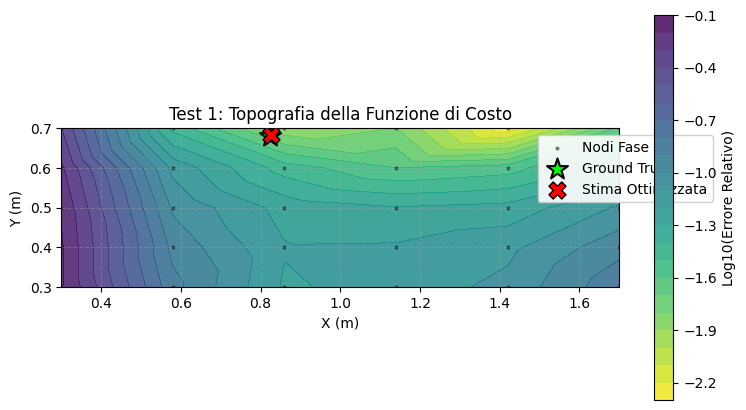


--------------------------------------------------
 TEST 2 OF 5
--------------------------------------------------
1. Creation Ground Truth: Cavity hidden in (1.3248, 0.5395)...

2. Starting inversion...

Starting inverse Multi-Grid with Multi-Start (Memory-Optimized)...
--> PHASE 1: Scanning Coarse Grid (sequential)...

  [1/30] (0.300, 0.300) -> err=7.1734e-01

  [2/30] (0.300, 0.400) -> err=7.0826e-01

  [3/30] (0.300, 0.500) -> err=6.6922e-01

  [4/30] (0.300, 0.600) -> err=5.7137e-01

  [5/30] (0.300, 0.700) -> err=4.3346e-01

  [6/30] (0.580, 0.300) -> err=1.6685e-01

  [7/30] (0.580, 0.400) -> err=1.4122e-01

  [8/30] (0.580, 0.500) -> err=1.0747e-01

  [9/30] (0.580, 0.600) -> err=7.0552e-02

  [10/30] (0.580, 0.700) -> err=3.5166e-02

  [11/30] (0.860, 0.300) -> err=4.5291e-02

  [12/30] (0.860, 0.400) -> err=3.9507e-02

  [13/30] (0.860, 0.500) -> err=2.7832e-02

  [14/30] (0.860, 0.600) -> err=1.0707e-02

  [15/30] (0.860, 0.700) -> err=5.3680e-02

  [16/30] (1.140, 0.300) 

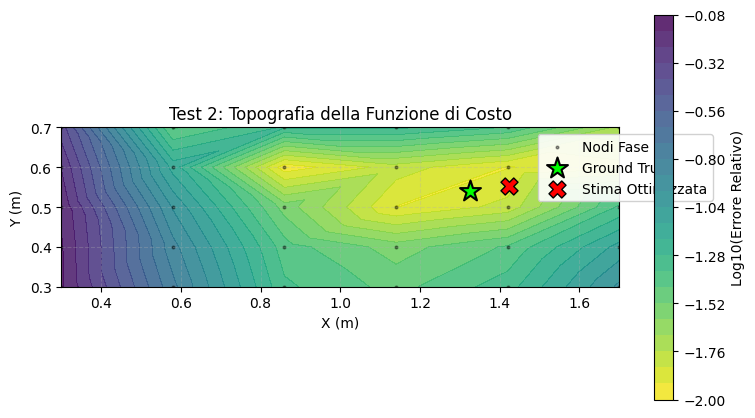


--------------------------------------------------
 TEST 3 OF 5
--------------------------------------------------
1. Creation Ground Truth: Cavity hidden in (0.5184, 0.3624)...

2. Starting inversion...

Starting inverse Multi-Grid with Multi-Start (Memory-Optimized)...
--> PHASE 1: Scanning Coarse Grid (sequential)...

  [1/30] (0.300, 0.300) -> err=4.2426e-01

  [2/30] (0.300, 0.400) -> err=4.1222e-01

  [3/30] (0.300, 0.500) -> err=3.7613e-01

  [4/30] (0.300, 0.600) -> err=2.9393e-01

  [5/30] (0.300, 0.700) -> err=1.9570e-01

  [6/30] (0.580, 0.300) -> err=4.0216e-02

  [7/30] (0.580, 0.400) -> err=6.6453e-02

  [8/30] (0.580, 0.500) -> err=1.0324e-01

  [9/30] (0.580, 0.600) -> err=1.3717e-01

  [10/30] (0.580, 0.700) -> err=1.5023e-01

  [11/30] (0.860, 0.300) -> err=1.5691e-01

  [12/30] (0.860, 0.400) -> err=1.6841e-01

  [13/30] (0.860, 0.500) -> err=1.7381e-01

  [14/30] (0.860, 0.600) -> err=1.6954e-01

  [15/30] (0.860, 0.700) -> err=1.5285e-01

  [16/30] (1.140, 0.300) 

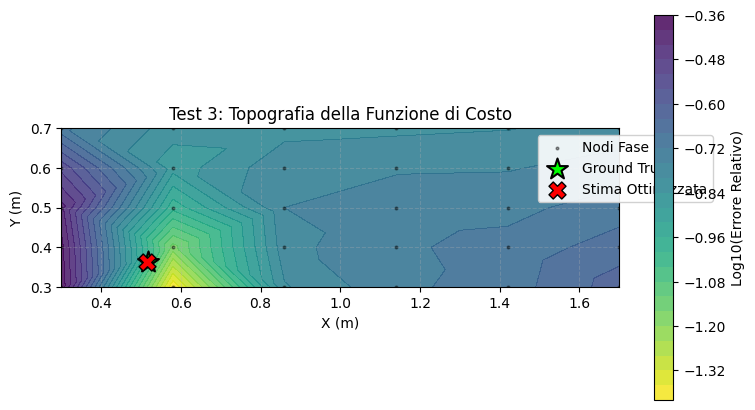


--------------------------------------------------
 TEST 4 OF 5
--------------------------------------------------
1. Creation Ground Truth: Cavity hidden in (0.3813, 0.6465)...

2. Starting inversion...

Starting inverse Multi-Grid with Multi-Start (Memory-Optimized)...
--> PHASE 1: Scanning Coarse Grid (sequential)...

  [1/30] (0.300, 0.300) -> err=4.5417e-01

  [2/30] (0.300, 0.400) -> err=4.3495e-01

  [3/30] (0.300, 0.500) -> err=3.8946e-01

  [4/30] (0.300, 0.600) -> err=2.9307e-01

  [5/30] (0.300, 0.700) -> err=1.5900e-01

  [6/30] (0.580, 0.300) -> err=8.9505e-02

  [7/30] (0.580, 0.400) -> err=9.0730e-02

  [8/30] (0.580, 0.500) -> err=1.1264e-01

  [9/30] (0.580, 0.600) -> err=1.4634e-01

  [10/30] (0.580, 0.700) -> err=1.7269e-01

  [11/30] (0.860, 0.300) -> err=1.6949e-01

  [12/30] (0.860, 0.400) -> err=1.8020e-01

  [13/30] (0.860, 0.500) -> err=1.8883e-01

  [14/30] (0.860, 0.600) -> err=1.9276e-01

  [15/30] (0.860, 0.700) -> err=1.9239e-01

  [16/30] (1.140, 0.300) 

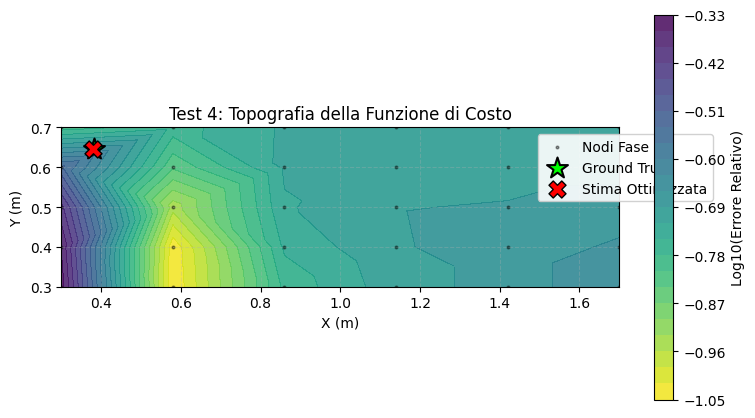


--------------------------------------------------
 TEST 5 OF 5
--------------------------------------------------
1. Creation Ground Truth: Cavity hidden in (1.1416, 0.5832)...

2. Starting inversion...

Starting inverse Multi-Grid with Multi-Start (Memory-Optimized)...
--> PHASE 1: Scanning Coarse Grid (sequential)...

  [1/30] (0.300, 0.300) -> err=7.0184e-01

  [2/30] (0.300, 0.400) -> err=6.9341e-01

  [3/30] (0.300, 0.500) -> err=6.5553e-01

  [4/30] (0.300, 0.600) -> err=5.5987e-01

  [5/30] (0.300, 0.700) -> err=4.2609e-01

  [6/30] (0.580, 0.300) -> err=1.5890e-01

  [7/30] (0.580, 0.400) -> err=1.3529e-01

  [8/30] (0.580, 0.500) -> err=1.0469e-01

  [9/30] (0.580, 0.600) -> err=7.1377e-02

  [10/30] (0.580, 0.700) -> err=3.2723e-02

  [11/30] (0.860, 0.300) -> err=4.9152e-02

  [12/30] (0.860, 0.400) -> err=4.6396e-02

  [13/30] (0.860, 0.500) -> err=3.6204e-02

  [14/30] (0.860, 0.600) -> err=1.3078e-02

  [15/30] (0.860, 0.700) -> err=4.1581e-02

  [16/30] (1.140, 0.300) 

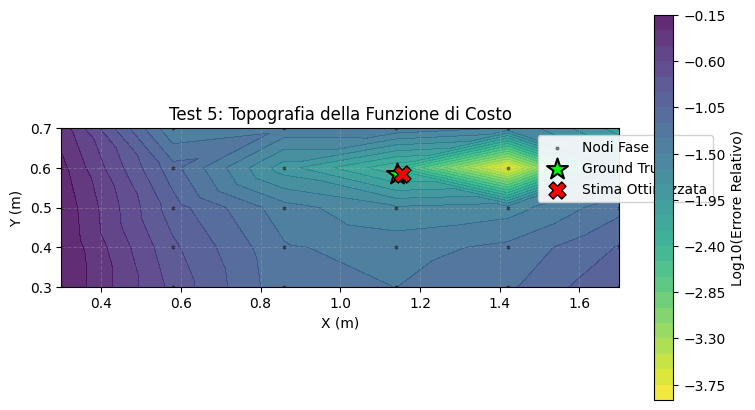


3. FINAL EVALUATION REPORT
Test 01: Real (0.824, 0.680) | Estimate (0.827, 0.682) | Error: 0.0030m | ✅ PASSED
Test 02: Real (1.325, 0.539) | Estimate (1.423, 0.554) | Error: 0.0990m | ⚠️ IMPRECISE
Test 03: Real (0.518, 0.362) | Estimate (0.516, 0.364) | Error: 0.0028m | ✅ PASSED
Test 04: Real (0.381, 0.646) | Estimate (0.380, 0.647) | Error: 0.0011m | ✅ PASSED
Test 05: Real (1.142, 0.583) | Estimate (1.154, 0.585) | Error: 0.0128m | ✅ PASSED
--------------------------------------------------
Mean Error:    0.0237 m
Maximum Error: 0.0990 m


In [12]:
run_multiple_inversion_tests(num_tests=5, seed=42)

* Precise almost in everything (excpet the test 2)
* we can try to change some value (iterations, tol, mesh size) to improve efficiency
* tempo: ~35 min/5 casi